# Model Comparison and Dataset Analysis

This notebook is split from `majorproject(1).ipynb`. Run cells from top to bottom.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os 

In [2]:
folder_path = r"C:\Users\Asus\Downloads\OneDrive_1_8-22-2026"
csv_files = glob.glob(os.path.join(folder_path,"*.csv"))
dataframes =[]
for file in csv_files:
    temp_df = pd.read_csv(file)
    dataframes.append(temp_df)

In [3]:
df =  pd.concat(dataframes,ignore_index=True)
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
print(df.iloc[:, -1].value_counts())

label
1    164673
0     93000
Name: count, dtype: int64


In [4]:
y = df["label"]
X = df.drop(columns=["label", "attack_cat", "id"])
X = pd.get_dummies(X, drop_first=True)
X = X.astype(np.float64)
X = X.to_numpy()
y = y.to_numpy()
X[X == np.inf] = np.nan
X[X == -np.inf] = np.nan

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state = 42)


In [6]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values= np.nan,strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [8]:
print(np.isnan(X_train).sum())
print(np.isnan(X_test).sum())

0
0


In [9]:
print(np.isinf(X_train).sum())
print(np.isinf(X_test).sum())

0
0


In [10]:
y_pred_en = le.transform(y_pred)
y_pred_dt_en = le.transform(y_pred_dt)
y_pred_rf_en = le.transform(y_pred_rf)

NameError: name 'le' is not defined

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# LOGISTIC REGRESSION
lr_acc = accuracy_score(y_test_encoded, y_pred_en)
lr_pre = precision_score(y_test_encoded,y_pred_en,average = 'weighted',zero_division=0)
lr_rec = recall_score(y_test_encoded, y_pred_en,average = 'weighted',zero_division=0)
lr_f1 = f1_score(y_test_encoded,y_pred_en,average = 'weighted',zero_division=0)
# DECISION TREE
dt_acc = accuracy_score(y_test_encoded, y_pred_dt_en)
dt_pre = precision_score(y_test_encoded,y_pred_dt_en,average = 'weighted',zero_division=0)
dt_rec = recall_score(y_test_encoded, y_pred_dt_en,average = 'weighted',zero_division=0)
dt_f1 = f1_score(y_test_encoded,y_pred_dt_en,average = 'weighted',zero_division=0)
# RANDOM FOREST
rf_acc = accuracy_score(y_test_encoded, y_pred_rf_en)
rf_pre = precision_score(y_test_encoded,y_pred_rf_en,average = 'weighted',zero_division=0)
rf_rec = recall_score(y_test_encoded,y_pred_rf_en,average = 'weighted',zero_division=0)
rf_f1 = f1_score(y_test_encoded,y_pred_rf_en,average = 'weighted',zero_division=0)
# XGBoost
xgb_acc = accuracy_score(y_test_encoded, y_pred_xgb)
xgb_pre = precision_score(y_test_encoded,y_pred_xgb,average = 'weighted',zero_division=0)
xgb_rec = recall_score(y_test_encoded, y_pred_xgb,average = 'weighted',zero_division=0)
xgb_f1 = f1_score(y_test_encoded,y_pred_xgb,average = 'weighted',zero_division=0)

In [ ]:
comparision = pd.DataFrame({
    "Model": [
        "LOGISTIC REGRESSION",
        "DECISION TREE",
        "RANDOM FOREST",
        "XGBoost"
    ],
    "Accuracy": [lr_acc, dt_acc, rf_acc, xgb_acc],
    "Precision": [lr_pre, dt_pre, rf_pre, xgb_pre],
    "Recall": [lr_rec, dt_rec, rf_rec, xgb_rec],
    "F1-Score": [lr_f1, dt_f1, rf_f1, xgb_f1]
})

print(comparision)

                 Model  Accuracy  Precision    Recall  F1-Score
0  LOGISTIC REGRESSION  0.903832   0.905972  0.903832  0.901924
1        DECISION TREE  0.938100   0.938129  0.938100  0.938114
2        RANDOM FOREST  0.950112   0.951087  0.950112  0.950336
3              XGBoost  0.941515   0.942092  0.941515  0.941692


In [ ]:
print("Total rows:", len(df))
print("Number of features:", X.shape[1])
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nClass distribution:")
print(df.iloc[:, -1].value_counts())

Total rows: 257673
Number of features: 193
Training rows: 206138
Testing rows: 51535

Class distribution:
label
1    164673
0     93000
Name: count, dtype: int64


In [ ]:
comparision = comparision.sort_values(by="F1-Score",ascending=False)
print(comparision)

                 Model  Accuracy  Precision    Recall  F1-Score
2        RANDOM FOREST  0.950112   0.951087  0.950112  0.950336
3              XGBoost  0.941515   0.942092  0.941515  0.941692
1        DECISION TREE  0.938100   0.938129  0.938100  0.938114
0  LOGISTIC REGRESSION  0.903832   0.905972  0.903832  0.901924


In [ ]:
from collections import Counter
print("Class Distribution: ")
print(Counter(y))

print("\nClass percentages")
print(pd.Series(y).value_counts(normalize = True)*100)


Class Distribution: 
Counter({np.int64(1): 164673, np.int64(0): 93000})

Class percentages
1    63.907744
0    36.092256
Name: proportion, dtype: float64


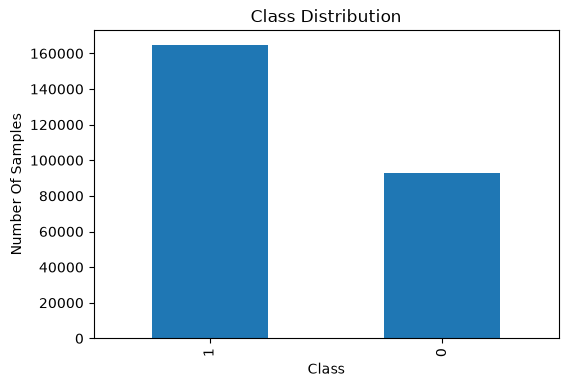

In [ ]:
class_counts = pd.Series(y).value_counts()
plt.figure(figsize=(6,4))
class_counts.plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number Of Samples")
plt.show()

In [ ]:
print(df["attack_cat"].value_counts())

attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": le.inverse_transform(y_pred_xgb)
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Attack Precision": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Attack Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Attack F1-Score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values(
    by="Attack Recall", ascending=False
).to_string(index=False))


              Model  Accuracy  Attack Precision  Attack Recall  Attack F1-Score
Logistic Regression  0.903832          0.891558       0.966768         0.927641
      Decision Tree  0.938100          0.951983       0.950883         0.951433
            XGBoost  0.941515          0.961812       0.945831         0.953755
      Random Forest  0.941768          0.977362       0.930219         0.953208
